# Práctica 2: Jauregui Arvilla Josue Emmanuel
# The Bag Of Words Binaria

In [242]:
# Leer Datos
def get_texts_from_file(path_corpus, path_truth):
    tr_txt = []  # aqui van los tuits
    tr_y = []  # etiquetas de las psicologas

    with open(path_corpus, "r", encoding="utf-8") as f_corpus, \
            open(path_truth, 'r', encoding="utf-8") as f_truth:
        for twitt in f_corpus:
            tr_txt += [twitt]

        for label in f_truth:
            tr_y += [label]
    return tr_txt, tr_y

In [243]:
# Guardar tweets de entrenamiento
tr_txt, tr_y = get_texts_from_file("./mex20_train.txt", "./mex20_train_labels.txt")

# Ver datos

In [244]:
import matplotlib.pyplot as plt
from collections import Counter

%matplotlib inline
print(Counter(tr_y))

Counter({'0\n': 3759, '1\n': 1519})


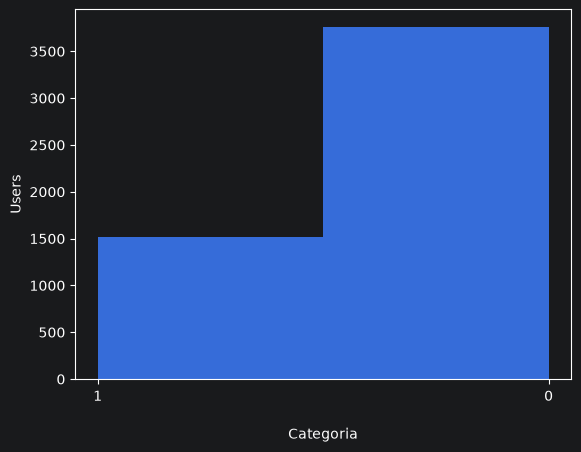

In [245]:
plt.hist(tr_y, bins=len(set(tr_y)))

plt.ylabel("Users")
plt.xlabel("Categoria")

plt.show()

# Token

In [246]:
tr_txt[61]

'🤣🤣🤣 mi vida, eres la mejor! Dí lo q digas y a la verga los haters heteropatriarcanormados! Block y be happy! 😘\n'

In [247]:
tr_txt[61].split()

['🤣🤣🤣',
 'mi',
 'vida,',
 'eres',
 'la',
 'mejor!',
 'Dí',
 'lo',
 'q',
 'digas',
 'y',
 'a',
 'la',
 'verga',
 'los',
 'haters',
 'heteropatriarcanormados!',
 'Block',
 'y',
 'be',
 'happy!',
 '😘']

In [248]:
import nltk

tokens = nltk.word_tokenize(tr_txt[61])
print(tokens)

['🤣🤣🤣', 'mi', 'vida', ',', 'eres', 'la', 'mejor', '!', 'Dí', 'lo', 'q', 'digas', 'y', 'a', 'la', 'verga', 'los', 'haters', 'heteropatriarcanormados', '!', 'Block', 'y', 'be', 'happy', '!', '😘']


In [249]:
from nltk.tokenize import TweetTokenizer

tokenizer = TweetTokenizer()

In [250]:
tokenizer.tokenize(tr_txt[61] + "www.youtube.com")

['🤣',
 '🤣',
 '🤣',
 'mi',
 'vida',
 ',',
 'eres',
 'la',
 'mejor',
 '!',
 'Dí',
 'lo',
 'q',
 'digas',
 'y',
 'a',
 'la',
 'verga',
 'los',
 'haters',
 'heteropatriarcanormados',
 '!',
 'Block',
 'y',
 'be',
 'happy',
 '!',
 '😘',
 'www.youtube.com']

In [251]:
corpus_palabras = []
for doc in tr_txt:
    corpus_palabras += tokenizer.tokenize(doc.lower())

In [252]:
len(set(corpus_palabras))

13117

In [253]:
fdist = nltk.FreqDist(corpus_palabras)

In [254]:
type(fdist)

nltk.probability.FreqDist

In [255]:
fdist

FreqDist({'que': 3111, 'de': 3094, ',': 3016, '.': 2604, 'la': 2269, 'a': 2205, 'y': 2098, 'no': 1819, 'me': 1475, '!': 1435, ...})

In [256]:
def sortFreqDist(freqdict):
    aux = [(freqdict[key], key)for key in freqdict]
    aux.sort()
    aux.reverse()
    return aux # se convierte en el diccionario

In [257]:
V = sortFreqDist(fdist)

In [258]:
V = V[:10000] # [(3111,'que')]

In [259]:
V

[(3111, 'que'),
 (3094, 'de'),
 (3016, ','),
 (2604, '.'),
 (2269, 'la'),
 (2205, 'a'),
 (2098, 'y'),
 (1819, 'no'),
 (1475, 'me'),
 (1435, '!'),
 (1399, '@usuario'),
 (1176, 'el'),
 (1117, 'en'),
 (946, 'se'),
 (848, 'es'),
 (802, 'verga'),
 (772, 'madre'),
 (752, 'los'),
 (749, 'con'),
 (715, 'por'),
 (704, '?'),
 (674, 'las'),
 (628, 'mi'),
 (627, 'un'),
 (620, 'te'),
 (617, 'ya'),
 (593, 'si'),
 (593, 'putos'),
 (592, 'lo'),
 (590, '"'),
 (578, 'putas'),
 (532, 'una'),
 (512, 'para'),
 (512, 'como'),
 (464, '...'),
 (456, 'pero'),
 (444, 'su'),
 (434, '😂'),
 (417, 'tu'),
 (384, 'loca'),
 (375, 'le'),
 (343, 'más'),
 (321, 'gorda'),
 (315, 'yo'),
 (313, 'del'),
 (308, 'al'),
 (288, 'cuando'),
 (276, 'o'),
 (258, 'bien'),
 (251, 'son'),
 (250, 'estoy'),
 (243, '¿'),
 (239, 'qué'),
 (232, 'porque'),
 (228, 'feas'),
 (223, 'ni'),
 (223, 'está'),
 (222, 'les'),
 (220, 'pinche'),
 (214, 'esta'),
 (213, 'puta'),
 (209, 'todos'),
 (208, ':'),
 (198, 'ser'),
 (196, 'puto'),
 (194, 'sus'),
 

In [260]:
dict_indices = dict()

cont = 0
for frecuencia, word in V:
    dict_indices[word] = cont
    cont += 1

In [261]:
dict_indices

{'que': 0,
 'de': 1,
 ',': 2,
 '.': 3,
 'la': 4,
 'a': 5,
 'y': 6,
 'no': 7,
 'me': 8,
 '!': 9,
 '@usuario': 10,
 'el': 11,
 'en': 12,
 'se': 13,
 'es': 14,
 'verga': 15,
 'madre': 16,
 'los': 17,
 'con': 18,
 'por': 19,
 '?': 20,
 'las': 21,
 'mi': 22,
 'un': 23,
 'te': 24,
 'ya': 25,
 'si': 26,
 'putos': 27,
 'lo': 28,
 '"': 29,
 'putas': 30,
 'una': 31,
 'para': 32,
 'como': 33,
 '...': 34,
 'pero': 35,
 'su': 36,
 '😂': 37,
 'tu': 38,
 'loca': 39,
 'le': 40,
 'más': 41,
 'gorda': 42,
 'yo': 43,
 'del': 44,
 'al': 45,
 'cuando': 46,
 'o': 47,
 'bien': 48,
 'son': 49,
 'estoy': 50,
 '¿': 51,
 'qué': 52,
 'porque': 53,
 'feas': 54,
 'ni': 55,
 'está': 56,
 'les': 57,
 'pinche': 58,
 'esta': 59,
 'puta': 60,
 'todos': 61,
 ':': 62,
 'ser': 63,
 'puto': 64,
 'sus': 65,
 'todo': 66,
 'soy': 67,
 'eso': 68,
 'tan': 69,
 'hdp': 70,
 'así': 71,
 'hasta': 72,
 'muy': 73,
 'hay': 74,
 '…': 75,
 'mis': 76,
 'este': 77,
 'mamar': 78,
 'quiero': 79,
 'q': 80,
 'nos': 81,
 'solo': 82,
 '¡': 83,
 '

In [262]:
import numpy as np

def build_bow_tr(tr_txt, V, dict_indices):
    BOW = np.zeros((len(tr_txt), len(V)), dtype=int)

    cont_doc = 0
    for tr in tr_txt:
        fdist_doc = nltk.FreqDist(tokenizer.tokenize(tr.lower()))

        for word in fdist_doc:
            if word in dict_indices:
                BOW[cont_doc, dict_indices[word]] = 1
        cont_doc += 1

    return BOW

In [263]:
BOW_tr = build_bow_tr(tr_txt, V, dict_indices)

In [264]:
BOW_tr

array([[0, 1, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 1, 0, ..., 0, 0, 0],
       ...,
       [0, 1, 0, ..., 0, 0, 0],
       [0, 0, 1, ..., 0, 0, 0],
       [0, 1, 1, ..., 0, 0, 0]], shape=(5278, 10000))

Counter({'0\n': 418, '1\n': 169})


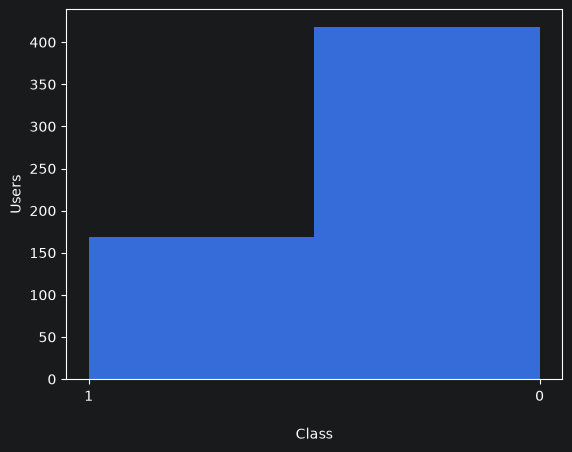

In [265]:
val_txt, val_y = get_texts_from_file("./mex20_val.txt", "./mex20_val_labels.txt")

print(Counter(val_y))
plt.hist(val_y, bins=len(set(val_y)))

plt.ylabel("Users")
plt.xlabel("Class")
plt.show()

In [266]:
BOW_val = build_bow_tr(val_txt, V, dict_indices)

In [267]:
BOW_val.shape

(587, 10000)

# Clasificacion

# Parte 1 de Clasificacion

In [268]:
tr_y = list(map(int, tr_y))
val_y = list(map(int, val_y))

from sklearn import svm
from sklearn.model_selection import GridSearchCV # Para varios experimentos y probar parametros
from sklearn import metrics
from sklearn.metrics import precision_recall_fscore_support

svm = svm.LinearSVC(class_weight='balanced')

# Parte 2
parameters = {'C': [.5, .12, .25, .5, 1, 2, 4]}
# varios experimentos a probar un parametro
grid = GridSearchCV(estimator=svm, param_grid=parameters, n_jobs=4, scoring="f1_macro", cv=5 )

grid.fit(BOW_tr, tr_y) # llevar a cabo entrenamiento sobre la bolsa de palabras de TRAIN

y_pred = grid.predict(BOW_val)

In [269]:
print(metrics.classification_report(val_y, y_pred))

              precision    recall  f1-score   support

           0       0.89      0.87      0.88       418
           1       0.70      0.74      0.72       169

    accuracy                           0.83       587
   macro avg       0.80      0.81      0.80       587
weighted avg       0.84      0.83      0.84       587



In [270]:
incorrect = []
for e in zip(val_y, y_pred, range(len(val_y))):
    if e[0] != e[1]: # Si la etiqueta anotada no coincide con la predicción
        incorrect += [e[2]] # dime el número de instancia dónde se equivoco

In [271]:
for e in incorrect:
    case = e
    if "madre" in val_txt[case].strip():
        print("Texto: ", val_txt[case].strip())
        print("Truth: ", val_y[case])
        print("Pred: ", y_pred[case])

Texto:  Al perro que se te acerque le parto su madre a si de facil
Truth:  1
Pred:  0
Texto:  @USUARIO Ya m tienen hasta la madre esos maes
Truth:  0
Pred:  1
Texto:  Amigos, Vero tiene toda la razón por eso no hay que ir a esa madre, mejor todos a Costeño a empedar.
Truth:  0
Pred:  1
Texto:  @USUARIO PA tener 80 estas a toda madre!
Truth:  0
Pred:  1
Texto:  Por está madre me agarré a vergazos con el de la combi y no le pagué, el puto decía que ya no valen.
Truth:  1
Pred:  0
Texto:  Ya van a ser las putas 8 y la pasarela no tiene para cuando empezar perra madre
Truth:  0
Pred:  1
Texto:  Políticos pseudoaficiomados que sólo en finales hablan de beisbol pueden ir mucho a chingar a su madre. Y peor cuando opinan.
Truth:  1
Pred:  0
Texto:  @USUARIO @USUARIO Hija de tu madre 😂😂😂😂🖕🏼🖕🏼🤚🏻
Truth:  0
Pred:  1
Texto:  La anciana madre de Freddie Mercury desmitifica a su hijo
Truth:  0
Pred:  1
Texto:  @USUARIO No tienen abuela madre vergüenza....
Truth:  1
Pred:  0
Texto:  El Gobierno Federa

In [273]:
from sklearn.feature_selection import SelectKBest, chi2

In [275]:
feats = SelectKBest(chi2, k=1000)
feats.fit(BOW_tr, tr_y)

SelectKBest(k=1000, score_func=<function chi2 at 0x00000133EFCCB1C0>)

In [276]:
best = feats.get_support(indices=True)

In [278]:
dict_indices

{'que': 0,
 'de': 1,
 ',': 2,
 '.': 3,
 'la': 4,
 'a': 5,
 'y': 6,
 'no': 7,
 'me': 8,
 '!': 9,
 '@usuario': 10,
 'el': 11,
 'en': 12,
 'se': 13,
 'es': 14,
 'verga': 15,
 'madre': 16,
 'los': 17,
 'con': 18,
 'por': 19,
 '?': 20,
 'las': 21,
 'mi': 22,
 'un': 23,
 'te': 24,
 'ya': 25,
 'si': 26,
 'putos': 27,
 'lo': 28,
 '"': 29,
 'putas': 30,
 'una': 31,
 'para': 32,
 'como': 33,
 '...': 34,
 'pero': 35,
 'su': 36,
 '😂': 37,
 'tu': 38,
 'loca': 39,
 'le': 40,
 'más': 41,
 'gorda': 42,
 'yo': 43,
 'del': 44,
 'al': 45,
 'cuando': 46,
 'o': 47,
 'bien': 48,
 'son': 49,
 'estoy': 50,
 '¿': 51,
 'qué': 52,
 'porque': 53,
 'feas': 54,
 'ni': 55,
 'está': 56,
 'les': 57,
 'pinche': 58,
 'esta': 59,
 'puta': 60,
 'todos': 61,
 ':': 62,
 'ser': 63,
 'puto': 64,
 'sus': 65,
 'todo': 66,
 'soy': 67,
 'eso': 68,
 'tan': 69,
 'hdp': 70,
 'así': 71,
 'hasta': 72,
 'muy': 73,
 'hay': 74,
 '…': 75,
 'mis': 76,
 'este': 77,
 'mamar': 78,
 'quiero': 79,
 'q': 80,
 'nos': 81,
 'solo': 82,
 '¡': 83,
 '

In [277]:
best

array([   1,    2,    4,    5,    8,    9,   10,   12,   15,   16,   17,
         22,   24,   27,   29,   31,   35,   36,   38,   39,   41,   42,
         43,   44,   46,   49,   50,   51,   52,   53,   54,   56,   57,
         58,   59,   60,   61,   62,   64,   65,   66,   67,   70,   73,
         76,   79,   80,   84,   86,   87,   88,   93,   94,   96,   97,
         98,   99,  101,  104,  105,  107,  108,  110,  111,  112,  113,
        114,  117,  119,  120,  122,  124,  126,  129,  131,  132,  134,
        135,  136,  137,  139,  143,  145,  153,  155,  157,  165,  166,
        167,  168,  171,  172,  173,  178,  179,  181,  183,  186,  187,
        191,  193,  194,  196,  198,  201,  202,  203,  208,  209,  216,
        219,  221,  222,  225,  229,  233,  236,  240,  241,  243,  244,
        245,  247,  248,  250,  253,  254,  255,  256,  258,  260,  261,
        264,  265,  268,  269,  275,  276,  277,  278,  279,  280,  281,
        282,  283,  286,  287,  289,  290,  292,  2

In [280]:
from wordcloud import WordCloud

In [282]:
wordcloud = WordCloud(width = 800, height = 400, background_color="black").generate_from_frequencies(dict_indices)

In [283]:
wordcloud